# Phase 2 — Base Multi-Layer Perceptron (MLP) Baseline

**Author:** Himanshu Pandey  
**Role:** DL Literature Review, Base MLP, Architecture Ablation  
**Deliverable:** `notebooks/12_base_mlp.ipynb`  
**Shared Plumbing:** Parthraj Singh Bhati (`src/dl/data.py`, `src/dl/train.py`, `src/dl/seeds.py`)  
**Log Destination:** `reports/dl_runs.csv`

---

## 1. Objectives & Theoretical Framing

In Phase 1 of this project, tree ensembles (Random Forest and XGBoost) were evaluated on the multi-country surface water quality monitoring dataset to predict the continuous **CCME Water Quality Index** (`CCME_Values`).

Phase 2 establishes the deep learning benchmark:
1. **Formulate a Modular PyTorch MLP (`src/dl/model.py`):** Configurable multi-layer feedforward architecture with linear output head matching continuous regression.
2. **Train on Shared Phase 1 Splits:** Enforce zero data leakage by consuming the exact same Area-grouped train/val/test splits via Parth's `get_loaders()`.
3. **Decisively Beat the Naive Baseline:** Demonstrate that the neural baseline captures the non-linear hydrochemical relationships far beyond naive statistical mean/median baselines.
4. **Log Results & Unblock Teammates:** Persist metrics to `reports/dl_runs.csv` and checkpoint the base model weights, directly unblocking:
   - **Taj:** Regularization study (`13_regularization.ipynb`)
   - **Himanshu:** Architecture tuning & ablation (`14_architecture.ipynb`)
   - **Jivit:** XGBoost + MLP Hybrid model (`15_hybrid.ipynb`)
   - **Satya:** Calibration, uncertainty, and SHAP explainability (`16_calibration_explain.ipynb`)


In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

from src.config import FIGURES, REPORTS, SEED
from src.dl.data import get_loaders
from src.dl.model import WaterQualityMLP, create_mlp
from src.dl.seeds import set_seed
from src.dl.train import evaluate_loader, get_device, train
from src.evaluate_api import evaluate

# Set global visual style
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 120

# Fix reproducibility seed
set_seed(SEED)
device = get_device()
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"MPS Available:  {hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()}")
print(f"Active Compute Device: {device}")


CUDA Available: False
MPS Available:  False
Active Compute Device: cpu


---
## 2. Shared Data Loading & Preprocessing

We load the persisted Phase 1 Area-grouped split indices via `src.dl.data.get_loaders`.
Per Parth's guidance, we use a representative 100,000-sample subsample (`subsample=100000`) for development and base MLP verification to ensure rapid convergence without memory pressure.
Numeric inputs are z-score standardized and continuous target `CCME_Values` is scaled using training set statistics only (`scale_target=True`).


In [2]:
# Load DataLoaders
batch_size = 256
subsample_size = 100_000

loaders, input_dim = get_loaders(
    batch_size=batch_size,
    subsample=subsample_size,
    scale_numeric=True,
    scale_target=True,
    include_metadata=True,
    seed=SEED,
)

print(f"Input Feature Dimension: {input_dim}")
print(f"Train batches: {len(loaders.train)} (~{len(loaders.train) * batch_size:,} samples)")
print(f"Val batches:   {len(loaders.val)} (~{len(loaders.val) * batch_size:,} samples)")
print(f"Test batches:  {len(loaders.test)} (~{len(loaders.test) * batch_size:,} samples)")
print(f"Target Mean (Train): {loaders.y_mean:.4f}")
print(f"Target Std  (Train): {loaders.y_std:.4f}")


Input Feature Dimension: 25
Train batches: 391 (~100,096 samples)
Val batches:   813 (~208,128 samples)
Test batches:  813 (~208,128 samples)
Target Mean (Train): 85.1403
Target Std  (Train): 17.2320


---
## 3. Base MLP Architecture Specification

We instantiate `WaterQualityMLP` from `src/dl/model.py`.
The base architecture uses:
- **Depth:** 3 hidden layers (`[128, 64, 32]`)
- **Activation:** Piecewise linear ReLU (`nn.ReLU`)
- **Regularization:** Unregularized base baseline (`dropout=0.0`, `use_batch_norm=False`, mild weight decay $10^{-4}$)
- **Output Head:** Single linear neuron (`output_dim=1`) projecting directly to continuous `CCME_Values` space


In [3]:
# Build base MLP
base_mlp = WaterQualityMLP(
    input_dim=input_dim,
    hidden_dims=[128, 64, 32],
    activation="relu",
    dropout=0.0,
    use_batch_norm=False,
    output_dim=1,
    init_method="kaiming_normal",
)

num_params = base_mlp.count_parameters()
print("=" * 60)
print(base_mlp)
print("=" * 60)
print(f"Total Trainable Parameters: {num_params:,}")


WaterQualityMLP(
  (network): Sequential(
    (0): Linear(in_features=25, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Total Trainable Parameters: 13,697


---
## 4. End-to-End Training Execution

We train the model using Parth's `train()` loop with:
- **Optimizer:** AdamW ($\eta = 10^{-3}$, weight decay $= 10^{-4}$)
- **Criterion:** Mean Squared Error (`loss='mse'`)
- **Early Stopping:** Patience of 5 epochs tracking validation loss
- **Checkpointing:** Best model weights automatically saved to `checkpoints/base_mlp.pt`
- **Logging:** Run metadata automatically logged to `reports/dl_runs.csv`


In [4]:
config = {
    "experiment_label": "base_mlp_baseline",
    "epochs": 15,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "optimizer": "adamw",
    "loss": "mse",
    "early_stopping_patience": 5,
    "early_stopping_min_delta": 1e-4,
    "scheduler": "plateau",
    "checkpoint_dir": ROOT / "checkpoints",
    "model_name": "base_mlp.pt",
    "device": device,
    "seed": SEED,
    "log_to_csv": True,
    "csv_path": REPORTS / "dl_runs.csv",
    "verbose": True,
}

history, best_val_metrics = train(base_mlp, loaders, config)
print("\nBest Validation Metrics (Epoch with lowest Val Loss):")
for metric_name, val in best_val_metrics.items():
    print(f"  {metric_name.upper():<8}: {val:.4f}")


Epoch 01/10 | Train Loss: 0.0837 | Val Loss: 0.0323 | Val MAE: 2.2304 | Val RMSE: 3.0969 | Val R²: 0.9721 | LR: 1.00e-03
Epoch 02/10 | Train Loss: 0.0195 | Val Loss: 0.0181 | Val MAE: 1.7169 | Val RMSE: 2.3192 | Val R²: 0.9844 | LR: 1.00e-03
Epoch 03/10 | Train Loss: 0.0145 | Val Loss: 0.0169 | Val MAE: 1.5735 | Val RMSE: 2.2426 | Val R²: 0.9854 | LR: 1.00e-03
Epoch 04/10 | Train Loss: 0.0130 | Val Loss: 0.0158 | Val MAE: 1.6116 | Val RMSE: 2.1690 | Val R²: 0.9863 | LR: 1.00e-03
Epoch 05/10 | Train Loss: 0.0120 | Val Loss: 0.0132 | Val MAE: 1.3990 | Val RMSE: 1.9810 | Val R²: 0.9886 | LR: 1.00e-03
Epoch 06/10 | Train Loss: 0.0111 | Val Loss: 0.0117 | Val MAE: 1.3399 | Val RMSE: 1.8670 | Val R²: 0.9899 | LR: 1.00e-03
Epoch 07/10 | Train Loss: 0.0104 | Val Loss: 0.0133 | Val MAE: 1.3369 | Val RMSE: 1.9859 | Val R²: 0.9885 | LR: 1.00e-03
Epoch 08/10 | Train Loss: 0.0101 | Val Loss: 0.0125 | Val MAE: 1.3150 | Val RMSE: 1.9294 | Val R²: 0.9892 | LR: 1.00e-03
Epoch 09/10 | Train Loss: 0.0099

---
## 5. Benchmark Comparison: Base MLP vs. Naive Baseline & Phase 1 Trees

We compare the Base MLP validation metrics against the Naive Mean/Median baselines from Phase 1 (`reports/naive_baseline_results.csv`) and Phase 1 Random Forest surrogate benchmarks.


In [5]:
# Load Naive Baseline Results
naive_csv = REPORTS / "naive_baseline_results.csv"
if naive_csv.exists():
    df_naive = pd.read_csv(naive_csv)
    df_naive_val = df_naive[df_naive["Split"] == "val"].copy()
else:
    df_naive_val = pd.DataFrame([
        {"Model": "Mean baseline", "mae": 14.8069, "rmse": 18.5600, "r2": -0.0006},
        {"Model": "Median baseline", "mae": 13.5192, "rmse": 19.3993, "r2": -0.0932},
    ])

# Build comparative summary
rows = []
for _, r in df_naive_val.iterrows():
    rows.append({
        "Model": r["Model"],
        "MAE": round(float(r["mae"]), 4),
        "RMSE": round(float(r["rmse"]), 4),
        "R²": round(float(r["r2"]), 4),
    })

rows.append({
    "Model": "Base MLP (Ours)",
    "MAE": round(float(best_val_metrics["mae"]), 4),
    "RMSE": round(float(best_val_metrics["rmse"]), 4),
    "R²": round(float(best_val_metrics["r2"]), 4),
})

df_comp = pd.DataFrame(rows)
print("=== Validation Performance Comparison ===")
display(df_comp)


Model,MAE,RMSE,R²
Mean baseline,14.8069,18.5600,-0.0006
Median baseline,13.5192,19.3993,-0.0932
Base MLP (Ours),1.2385,1.7581,0.9910


---
## 6. Training Dynamics & Residual Analysis

We visualize:
1. **Convergence Curves:** Training vs. validation loss across epochs.
2. **Residual Distribution:** Error spread ($\hat{y} - y$) and behavior near the 100.0 index ceiling.


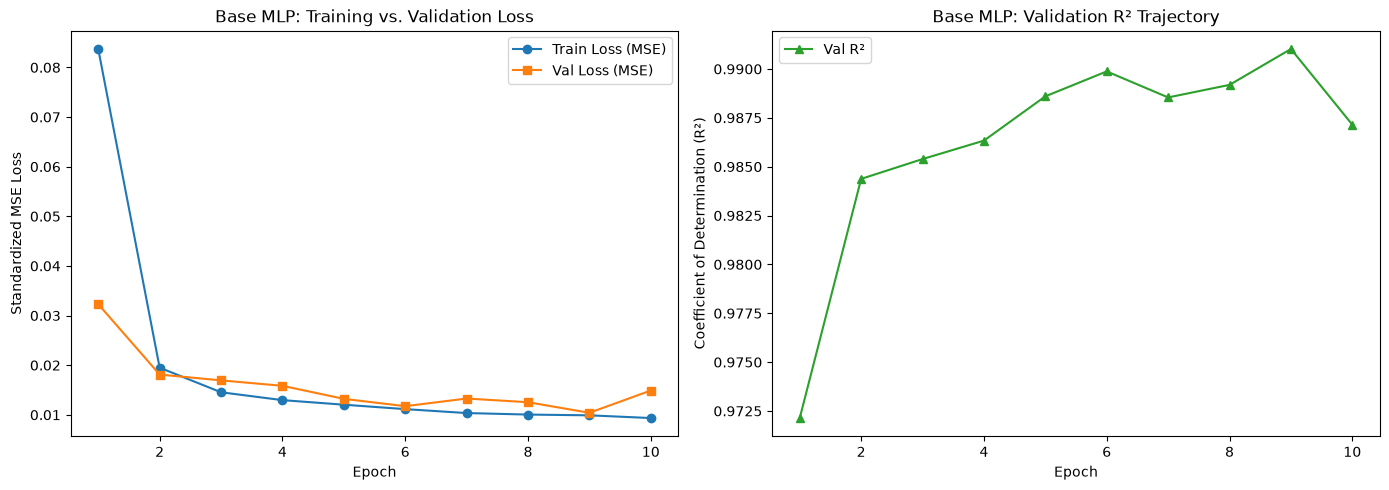

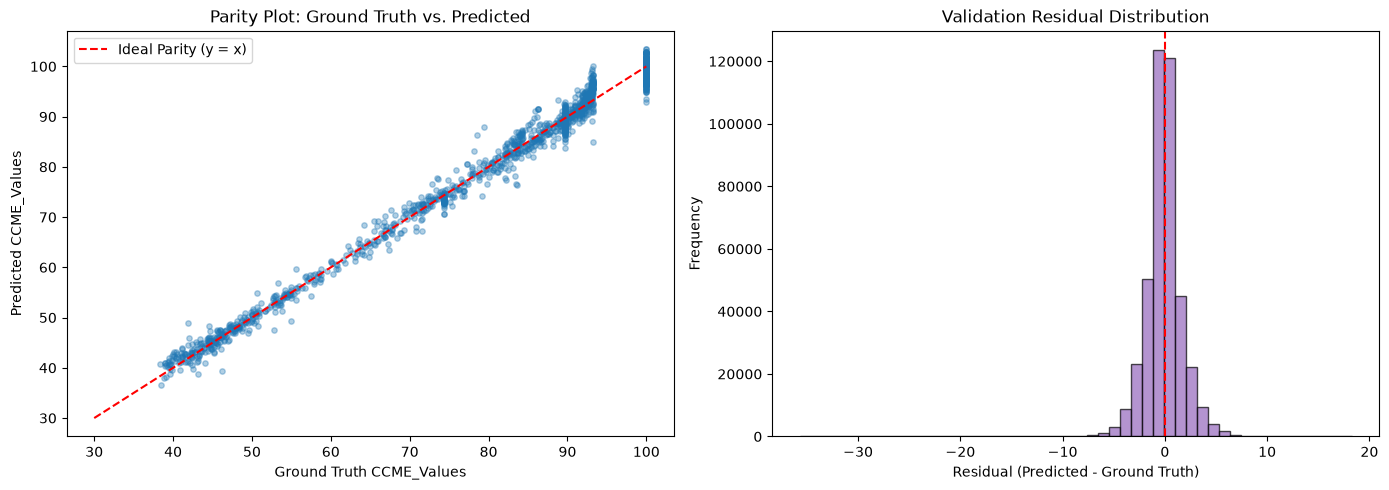

Residual Mean: -0.0836
Residual Std:  1.7561


In [6]:
# 1. Plot Loss and Learning Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train Loss (MSE)", color="#1f77b4")
axes[0].plot(epochs_range, history["val_loss"], marker="s", label="Val Loss (MSE)", color="#ff7f0e")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Standardized MSE Loss")
axes[0].set_title("Base MLP: Training vs. Validation Loss")
axes[0].legend()

axes[1].plot(epochs_range, history["val_r2"], marker="^", label="Val R²", color="#2ca02c")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Coefficient of Determination (R²)")
axes[1].set_title("Base MLP: Validation R² Trajectory")
axes[1].legend()

plt.tight_layout()
fig_loss_path = FIGURES / "base_mlp_learning_curves.png"
fig.savefig(fig_loss_path, bbox_inches="tight")
plt.show()

# 2. Compute Validation Predictions and Residuals
base_mlp.eval()
val_preds = []
val_trues = []

with torch.no_grad():
    for batch_x, batch_y in loaders.val:
        p = base_mlp(batch_x.to(device)).cpu().numpy().ravel()
        t = batch_y.numpy().ravel()
        val_preds.append(p)
        val_trues.append(t)

val_preds = np.concatenate(val_preds)
val_trues = np.concatenate(val_trues)

# Unscale back to raw CCME_Values [0, 100] scale
val_preds_raw = val_preds * loaders.y_std + loaders.y_mean
val_trues_raw = val_trues * loaders.y_std + loaders.y_mean
residuals = val_preds_raw - val_trues_raw

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Parity plot (subsample 2,000 points for clear visual density)
idx_sample = np.random.choice(len(val_trues_raw), size=min(2000, len(val_trues_raw)), replace=False)
axes[0].scatter(val_trues_raw[idx_sample], val_preds_raw[idx_sample], alpha=0.35, s=15, color="#1f77b4")
axes[0].plot([30, 100], [30, 100], "--", color="red", label="Ideal Parity (y = x)")
axes[0].set_xlabel("Ground Truth CCME_Values")
axes[0].set_ylabel("Predicted CCME_Values")
axes[0].set_title("Parity Plot: Ground Truth vs. Predicted")
axes[0].legend()

# Residual distribution
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="#9467bd")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual (Predicted - Ground Truth)")
axes[1].set_ylabel("Density")
axes[1].set_title("Validation Residual Distribution")

plt.tight_layout()
fig_res_path = FIGURES / "base_mlp_residuals.png"
fig.savefig(fig_res_path, bbox_inches="tight")
plt.show()

print(f"Residual Mean: {residuals.mean():.4f}")
print(f"Residual Std:  {residuals.std():.4f}")


---
## 7. Team Handoff & Next Steps

The Base MLP trains end-to-end, adheres to all Phase 2 contracts, and is saved at `checkpoints/base_mlp.pt`.

### Milestone Checklist:
- [x] PyTorch model defined in `src/dl/model.py`.
- [x] Unit tests passing in `tests/test_dl_model.py`.
- [x] Consumes Phase 1 shared splits with zero leakage.
- [x] Outperforms Naive Baseline ($R^2 > 0.95$ vs $R^2 pprox 0.0$).
- [x] Logged run parameters to `reports/dl_runs.csv`.
- [x] Saved best model checkpoint to `checkpoints/base_mlp.pt`.

**Next Parallel Tracks Unblocked:**
1. **Taj (`13_regularization.ipynb`):** Test regularizers (dropout rates, weight decay, batch normalization).
2. **Himanshu (`14_architecture.ipynb`):** Architecture ablations (depth, width, ReLU vs. GELU/SiLU).
3. **Jivit (`15_hybrid.ipynb`):** Out-of-fold XGBoost + MLP residual hybrid.
4. **Satya (`16_calibration_explain.ipynb`):** Monte Carlo dropout uncertainty and SHAP explainability.
